# NGC4567 and NGC4568: R-band and velocity segmentation

**2026-11-10 | MAUVE exploratory analysis**

[Shared workflow](https://chatgpt.com/s/t_6af33b62b26481919769d2055a7b3218).
Compare **A** (R-band light), **B** (R band and stellar velocity), and **C** (R band, stars and downweighted Hα).
Each valid Voronoi bin receives one galaxy label. Unmasked spaxels without a bin use the local photometric model.
The binary map describes projected membership. In the overlap, a single fitted velocity can mix light from both galaxies, and ionized gas can move differently from the stars. The map cannot recover the original component spectra.

## Inputs and footprint

Use the local MUSE-synthesized `R_FLUX` for the first run in place of the SDSS r image proposed in the shared thread. It is already on the MUSE grid. Use the SIMBAD crosswalk for nuclei, and the SDSS-derived inclinations and PAs in [Watts et al. (2023), Table 1](https://arxiv.org/abs/2303.07549) for the isophotal geometry. nGIST stellar KIN and gas BIN maps are used in their native relative velocity frame. The spatial mask defines the usable footprint. Only genuinely binned spaxels share kinematic evidence. Stellar S/N > 25 is kept as a separate quality mask.

In [1]:
%matplotlib inline

from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.wcs import WCS
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.lines import Line2D
from scipy.optimize import least_squares
from scipy.special import expit, gammaincinv
from scipy.ndimage import label as connected_components

ROOT = Path.cwd()
CUBE = "NGC4567_8"
GALAXIES = ["NGC4567", "NGC4568"]
PRODUCT = ROOT / "v3tk_v7.6.8" / CUBE
SEED_CUTS = [0.60, 0.55, 0.65]  # axial fraction from the 4567 nucleus to the 4568 nucleus
N_FOLDS = 6
CORE_EXCLUSION = 3.0  # arcsec
MIN_HA_SN = 5.0
MAX_V_ERROR = {"Stars": 20.0, "Hα": 15.0}  # km/s
SCATTER_FLOOR = 5.0  # km/s

def read_maps(suffix, names):
    with fits.open(PRODUCT / f"{CUBE}_{suffix}.fits", memmap=True) as hdus:
        maps = {name: hdus[name].data.astype(float) for name in names}
        grids = {name: WCS(hdus[name].header).celestial for name in names}
    return maps, grids

kin, wk = read_maps("kin_maps", ["V", "FORM_ERR_V", "SNR_POSTFIT"])
gas, wg = read_maps("gas_bin_maps_further", [
    "BIN_ID", "V_STARS2", "HA6562_VEL", "HA6562_VEL_ERR", "HA6562_FLUX", "HA6562_FLUX_ERR"
])
spatial, ws = read_maps("spatial_binning_maps_further", ["BINID", "FLUX"])
wcs = wk["V"]
ny, nx = kin["V"].shape
grid_x, grid_y = [0, nx - 1, 0, nx - 1, nx / 2], [0, 0, ny - 1, ny - 1, ny / 2]
sky_check = wcs.pixel_to_world(grid_x, grid_y)
for grids, maps in [(wk, kin), (wg, gas), (ws, spatial)]:
    for name, grid in grids.items():
        assert maps[name].shape == (ny, nx), name
        assert np.max(sky_check.separation(grid.pixel_to_world(grid_x, grid_y)).arcsec) < 1e-4, name
np.testing.assert_array_equal(spatial["BINID"], gas["BIN_ID"])
np.testing.assert_array_equal(kin["V"], gas["V_STARS2"])

cube_row = pd.read_csv(ROOT / "cube_centers_v3tk.csv").set_index("ID").loc[CUBE]
assert (cube_row.ny, cube_row.nx) == (ny, nx)
catalog = pd.read_csv(ROOT / "simbad_object_crosswalk.csv").set_index("component").loc[GALAXIES]
centres = SkyCoord(catalog.ra_deg.to_numpy(), catalog.dec_deg.to_numpy(), unit="deg")
cx, cy = wcs.world_to_pixel(centres)
assert np.all((0 <= cx) & (cx < nx) & (0 <= cy) & (cy < ny))
inclination = pd.read_csv(ROOT / "MAUVE_Inclination.dat", sep=r"\s+", comment="#",
                         header=None, names=["galaxy", "inclination"]).set_index("galaxy").loc[GALAXIES, "inclination"]
colours = {}
for line in (ROOT / "MAUVE_galaxy_colors.dat").read_text().splitlines():
    fields = line.split()
    if len(fields) >= 4 and fields[1] in GALAXIES:
        colours[fields[1]] = fields[3]
assert set(colours) == set(GALAXIES)

footprint = np.isfinite(gas["BIN_ID"]) & (gas["BIN_ID"] >= 0)
py, px = np.nonzero(footprint)
ids, first, inverse, counts = np.unique(gas["BIN_ID"][footprint], return_index=True,
                                       return_inverse=True, return_counts=True)
assert np.all((ids >= 0) & (ids == np.floor(ids)))
bx = np.bincount(inverse, weights=px) / counts
by = np.bincount(inverse, weights=py) / counts
bin_icrs = wcs.pixel_to_world(bx, by).icrs
bin_sky = SkyCoord(ra=bin_icrs.ra, dec=bin_icrs.dec, frame="icrs")

def per_bin(image):
    values = image[footprint]
    np.testing.assert_array_equal(values, values[first][inverse])
    return values[first]

star = per_bin(kin["V"])
star_err = per_bin(kin["FORM_ERR_V"])
ha = per_bin(gas["HA6562_VEL"])
ha_err = per_bin(gas["HA6562_VEL_ERR"])
ha_flux = per_bin(gas["HA6562_FLUX"])
ha_flux_err = per_bin(gas["HA6562_FLUX_ERR"])
ha_sn = np.divide(ha_flux, ha_flux_err, out=np.full(len(ids), np.nan), where=ha_flux_err > 0)
tracers = {
    "Stars": (star, star_err, np.ones(len(ids), dtype=bool)),
    "Hα": (ha, ha_err, ha_sn >= MIN_HA_SN),
}
offsets = []
for centre in centres:
    east, north = centre.spherical_offsets_to(bin_sky)
    offsets.append((east.arcsec, north.arcsec))
east12, north12 = centres[0].spherical_offsets_to(centres[1])
axis = np.array([east12.arcsec, north12.arcsec])
separation = np.linalg.norm(axis)
east, north = offsets[0]
fraction = (axis[0] * east + axis[1] * north) / separation**2
assert np.isfinite(fraction).all()
distance = np.array([np.hypot(e, n) for e, n in offsets])
print(f"{len(ids):,} distinct bins cover {footprint.sum():,} spaxels on a {nx} × {ny} grid.")
print(f"Cube centre CSV (x, y) = ({cube_row.center_x}, {cube_row.center_y}); nucleus separation = {separation:.1f} arcsec.")
display(catalog[["ra_deg", "dec_deg", "coordinate_bibcode"]].assign(x=cx, y=cy, inclination_deg=inclination))
postfit_snr = per_bin(kin["SNR_POSTFIT"])
snr25 = np.isfinite(postfit_snr) & (postfit_snr > 25)
with fits.open(PRODUCT / f"{CUBE}_mask.fits") as hdus:
    mask_column = hdus["MASKFILE"].data["MASK"]
    assert mask_column.size == ny * nx and np.isin(mask_column, [0, 1]).all()
    usable_pixels = mask_column.reshape(ny, nx) == 0
assert not np.any(footprint & ~usable_pixels)
unbinned = usable_pixels & ~footprint
print(f"Usable pixels: {usable_pixels.sum():,}; without a Voronoi bin: {unbinned.sum():,}.")

31,846 distinct bins cover 510,118 spaxels on a 971 × 1059 grid.
Cube centre CSV (x, y) = (486, 530); nucleus separation = 73.5 arcsec.
Usable pixels: 510,118; without a Voronoi bin: 0.


,ra_deg,dec_deg,coordinate_bibcode,x,y,inclination_deg
component,,,,,,
NGC4567,189.136242,11.257977,2020yCat.1350....0G,520.638848,782.511158,49
NGC4568,189.142883,11.238631,2006AJ....131.1163S,403.365187,434.286432,70


## 1. Put the two elliptical coordinate systems on the R-band image

The SIMBAD centres set the origins. The VERTICO inclinations and position angles set the flattened shape and orientation. For each galaxy, rotate the east and north offsets so that $x'_g$ is along the major axis (PA measured east of north) and $y'_g$ is along the minor axis. The projected axis ratio is $q_g^2=\cos^2 i_g+0.2^2\sin^2 i_g$. Every point on an ellipse has the same semi-major-axis radius $R_g=\sqrt{x_g'^2+(y_g'/q_g)^2}$.

The ellipses mark the same sample radii for each galaxy. Where they overlap, the same sky position has one elliptical radius relative to each centre. The dashed lines delimit the strip held out from the fiducial light fit and velocity training.


In [2]:
PA_PHOT = np.array([251., 211.])
np.testing.assert_array_equal(inclination.to_numpy(), [49, 70])
q = np.hypot(np.cos(np.deg2rad(inclination.to_numpy())), 0.2 * np.sin(np.deg2rad(inclination.to_numpy())))
vri_path = ROOT.parent / "v3tk_to_VRI" / f"{CUBE}_DATACUBE_FINAL_WCS_Pall_mad_red_v3tk_VRI.fits"
with fits.open(vri_path) as hdus:
    r_flux = hdus["R_FLUX"].data.astype(float)
    r_wcs = WCS(hdus["R_FLUX"].header).celestial
assert r_flux.shape == usable_pixels.shape
assert np.max(sky_check.separation(r_wcs.pixel_to_world(grid_x, grid_y)).arcsec) < 1e-4

uy, ux = np.nonzero(usable_pixels)
sky = wcs.pixel_to_world(ux, uy).icrs
sky = SkyCoord(ra=sky.ra, dec=sky.dec, frame="icrs")
east_north = [centre.spherical_offsets_to(sky) for centre in centres]
coords = np.array([(east.arcsec, north.arcsec) for east, north in east_north])
t = (axis[0] * coords[0, 0] + axis[1] * coords[0, 1]) / separation**2
assert np.isfinite(t).all()
angle = np.deg2rad(PA_PHOT)[:, None]
east, north = coords[:, 0], coords[:, 1]
major = east * np.sin(angle) + north * np.cos(angle)
minor = east * np.cos(angle) - north * np.sin(angle)
radii = np.hypot(major, minor / q[:, None])
r_obs = r_flux[usable_pixels]
sample = (np.isfinite(r_obs) & (r_obs > 0) & (np.hypot(east, north).min(axis=0) > CORE_EXCLUSION)
          & (ux % 5 == 0) & (uy % 5 == 0))
holdout = ((ux // 30 + 2 * (uy // 30)) % 5) == 0


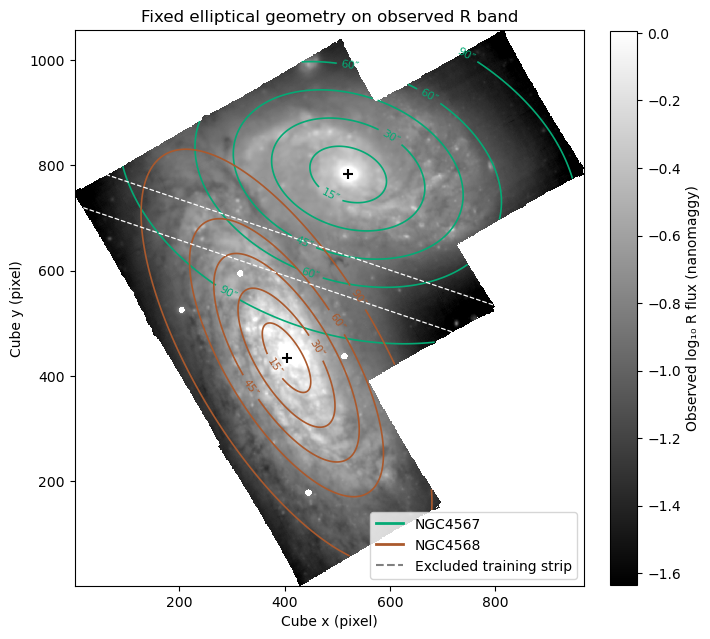

,Galaxy,Inclination (deg),PA (deg east of north),Projected axis ratio
0,NGC4567,49,251.0,0.673
1,NGC4568,70,211.0,0.390


In [3]:

from matplotlib.collections import LineCollection

OUT = ROOT / "20261110_NGC4567_8_segmentation"
OUT.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 10})
label_cmap = ListedColormap([colours[g] for g in GALAXIES])
label_norm = BoundaryNorm([0.5, 1.5, 2.5], label_cmap.N)
def panel(ax, image, title, *, show_light_edge=False, **kwargs):
    im = ax.imshow(image, origin="lower", interpolation="nearest", rasterized=True, **kwargs)
    ax.set(title=title, xlim=(ux.min(), ux.max()), ylim=(uy.min(), uy.max()))
    if show_light_edge:
        ax.contour(light_edge, levels=[0], colors="white", linewidths=0.8, alpha=0.8)
    ax.scatter(cx, cy, marker="+", color="black", s=45)
    return im

def show_save(fig, name):
    for extension in ["png", "pdf"]:
        fig.savefig(OUT / f"{name}.{extension}", dpi=160)
    display(fig)
    plt.close(fig)


CUT = SEED_CUTS[0]

def on_sky(values):
    image = np.full((ny, nx), np.nan)
    image[usable_pixels] = values
    return image

observed_light = on_sky(np.log10(np.where(r_obs > 0, r_obs, np.nan)))
light_limits = dict(vmin=np.nanpercentile(observed_light, 2), vmax=np.nanpercentile(observed_light, 99.5))
galaxy_handles = [Line2D([], [], color=colours[g], lw=2, label=g) for g in GALAXIES]

fig, ax = plt.subplots(figsize=(7, 7), layout="constrained")
im = panel(ax, observed_light, "Fixed elliptical geometry on observed R band", cmap="gray", **light_limits)
for radius, galaxy in zip(radii, GALAXIES):
    curves = ax.contour(on_sky(radius), levels=[15, 30, 45, 60, 90], colors=colours[galaxy], linewidths=1.2)
    ax.clabel(curves, fmt='%d″', fontsize=8)
ax.contour(on_sky(t), levels=[1 - CUT, CUT], colors="white", linestyles="--", linewidths=0.9)
ax.legend(handles=galaxy_handles + [Line2D([], [], color="gray", ls="--", label="Excluded training strip")],
          loc="lower right")
ax.set(xlabel="Cube x (pixel)", ylabel="Cube y (pixel)")
fig.colorbar(im, ax=ax, shrink=.8, label="Observed log₁₀ R flux (nanomaggy)")
show_save(fig, "01_elliptical_geometry")
display(pd.DataFrame({"Galaxy": GALAXIES, "Inclination (deg)": inclination.to_numpy(),
                      "PA (deg east of north)": PA_PHOT, "Projected axis ratio": q}).round(3))



## 2. Fit the light profiles and find where they cross

Each ellipse gets a modeled brightness from its galaxy's Sérsic profile,
$I_g(R_g)=I_{e,g}\exp\{-b_{n_g}[(R_g/R_{e,g})^{1/n_g}-1]\}$.
$R_{e,g}$ sets the scale, $n_g$ sets the profile shape, and $I_{e,g}$ is the brightness at $R_{e,g}$. Fit the **sum** $I_{67}+I_{68}$ to the observed R image in log flux, so both galaxies can contribute even on the outer sides. Exclude the central 3 arcsec around either nucleus and the companion-facing strip. Check the model on held-out 6 arcsec blocks in the outer regions before refitting on all seed pixels. The excluded interface receives extrapolated light profiles.

At each pixel, take the log ratio $\ln(I_{67}/I_{68})$. The white curve follows its zero contour. It looks nearly straight on this footprint because the two smooth profiles cross along a narrow, gently varying locus. Its shape comes from the two fitted brightness fields. For the actual **A** segmentation, sum each component's predicted flux over a Voronoi bin, then compare the two sums. Every pixel in that bin inherits the same label. This makes the binary edge follow bin boundaries.


In [4]:
def sersic(params, r):
    log_ie, re, n = params.reshape(2, 3).T[:, :, None]
    return np.exp(log_ie - gammaincinv(2 * n, 0.5) * ((r / re)**(1/n) - 1))

def fit_light(use):
    def residual(params):
        return np.log(sersic(params, radii[:, use]).sum(axis=0)) - np.log(r_obs[use])

    trials = [least_squares(residual, [-2., 40., n0, -2., 55., n1],
                           bounds=([-12., 3., 0.5] * 2, [3., 240., 6.] * 2),
                           loss="soft_l1", f_scale=0.25, x_scale="jac")
              for n0, n1 in [(1., 1.), (2.5, 1.), (1., 2.5)]]
    return min((trial for trial in trials if trial.success), key=lambda trial: trial.cost)

photo = {}
light_parameters = {}
photo_checks = []
for cut in SEED_CUTS:
    seeds = sample & ((t < 1 - cut) | (t > cut))
    fit = fit_light(seeds & ~holdout)
    test = seeds & holdout
    residual = np.log10(sersic(fit.x, radii[:, test]).sum(axis=0) / r_obs[test])
    fit = fit_light(seeds)
    light_parameters[cut] = fit.x
    model = sersic(fit.x, radii)
    pixel_d = np.log(model[0] / model[1])
    sums = np.array([np.bincount(inverse, weights=flux[footprint[usable_pixels]]) for flux in model])
    photo[cut] = (np.log(sums[0] / sums[1]), pixel_d)
    photo_checks.append({"strip edge": cut, "fit samples": seeds.sum(), "holdout samples": test.sum(),
                         "held-out median |dex|": np.median(abs(residual)),
                         "held-out P90 |dex|": np.quantile(abs(residual), .9),
                         "parameters at bounds": np.count_nonzero(fit.active_mask),
                         "Re 4567 (arcsec)": fit.x[1], "n 4567": fit.x[2],
                         "Re 4568 (arcsec)": fit.x[4], "n 4568": fit.x[5]})
assert all(np.isfinite(d).all() and np.isfinite(p).all() for d, p in photo.values())
display(pd.DataFrame(photo_checks).round(3))

,strip edge,fit samples,holdout samples,held-out median |dex|,held-out P90 |dex|,parameters at bounds,Re 4567 (arcsec),n 4567,Re 4568 (arcsec),n 4568
0,0.60,18051,3598,0.061,0.144,0,50.902,1.038,53.543,1.161
1,0.55,19198,3849,0.062,0.155,0,50.024,1.026,52.137,1.064
2,0.65,16978,3376,0.060,0.142,0,51.324,1.029,55.015,1.241


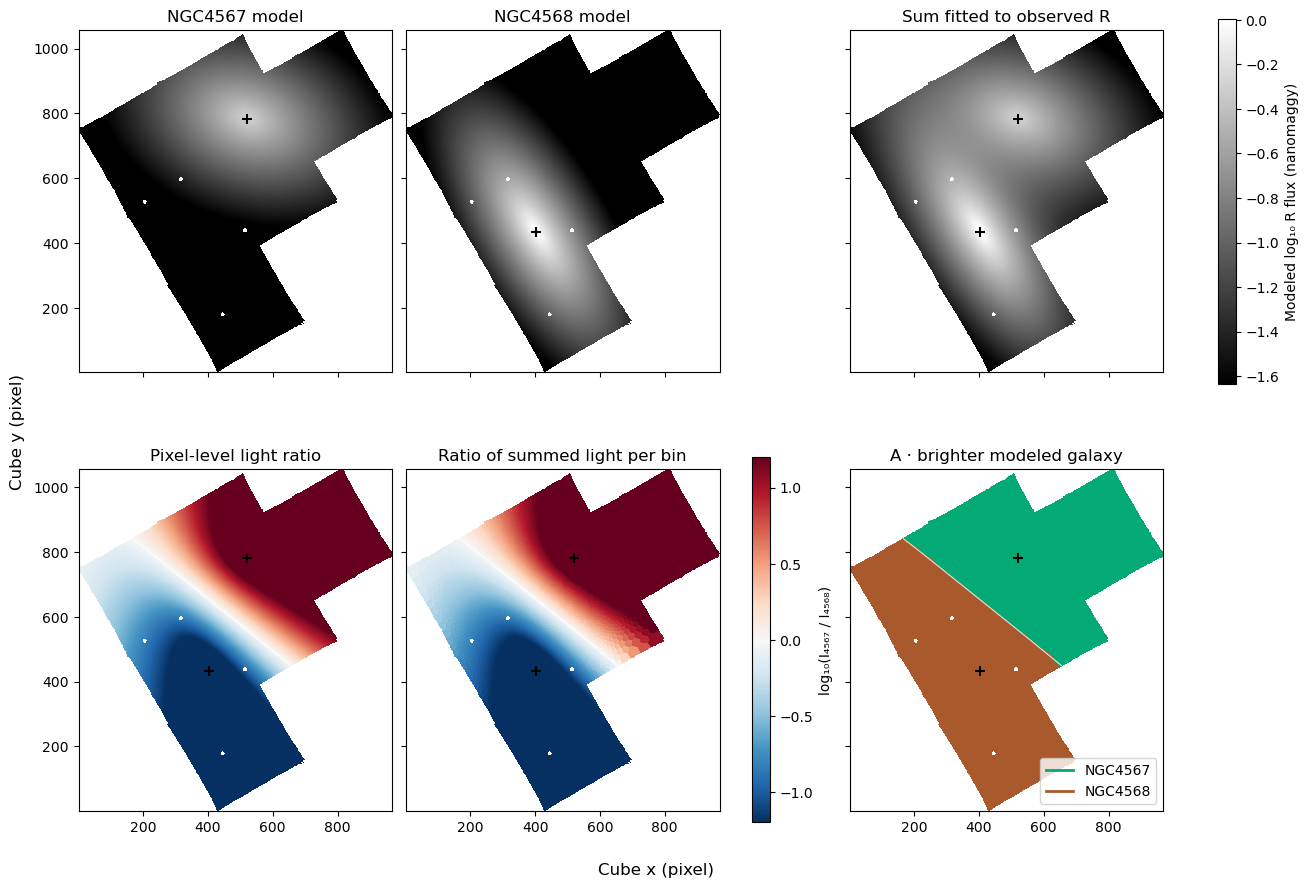

In [5]:

light_model = sersic(light_parameters[CUT], radii)
light_edge = on_sky(photo[CUT][1])
bin_light_ratio = np.full((ny, nx), np.nan)
bin_light_ratio[footprint] = photo[CUT][0][inverse] / np.log(10)

fig, axes = plt.subplots(2, 3, figsize=(13, 9), layout="constrained", sharex=True, sharey=True)
for ax, data, title in zip(axes[0], [light_model[0], light_model[1], light_model.sum(axis=0)],
                           ["NGC4567 model", "NGC4568 model", "Sum fitted to observed R"]):
    im = panel(ax, on_sky(np.log10(data)), title, cmap="gray", **light_limits)
fig.colorbar(im, ax=axes[0], shrink=.85, label="Modeled log₁₀ R flux (nanomaggy)")
for ax, data, title in zip(axes[1, :2], [light_edge / np.log(10), bin_light_ratio],
                           ["Pixel-level light ratio", "Ratio of summed light per bin"]):
    im = panel(ax, data, title, show_light_edge=True, cmap="RdBu_r", vmin=-1.2, vmax=1.2)
fig.colorbar(im, ax=axes[1, :2], shrink=.85, label="log₁₀(I₄₅₆₇ / I₄₅₆₈)")
a_light = np.where(bin_light_ratio < 0, 2, 1)
panel(axes[1, 2], np.ma.masked_invalid(np.where(footprint, a_light, np.nan)),
      "A · brighter modeled galaxy", show_light_edge=True, cmap=label_cmap, norm=label_norm)
axes[1, 2].legend(handles=galaxy_handles, loc="lower right")
fig.supxlabel("Cube x (pixel)")
fig.supylabel("Cube y (pixel)")
show_save(fig, "02_light_models_to_boundary")


## 3. Fit two rotating disks for each velocity tracer

Stars and Hα each have one measured velocity centroid per bin. For each tracer, fit an independent velocity field for each galaxy using bins on its outer side of the dashed strip. The centre and inclination stay fixed. The fitted kinematic PA sets the receding major axis and can differ from the photometric PA. With disk-plane radius $R=\sqrt{x'^2+(y'/\cos i)^2}$, the prediction is

$$
v_{\rm model}=v_0+A\frac{R}{\sqrt{R^2+R_t^2}}\frac{x'}{R}
               =v_0+A\frac{x'}{\sqrt{R^2+R_t^2}}.
$$

$v_0$ is the velocity zero point for that disk in the nGIST frame, $A$ is the projected outer rotation amplitude, and $R_t$ controls how quickly the rotation rises. Along the minor axis $x'=0$, so the prediction is $v_0$. On opposite sides of the major axis the rotation adds or subtracts velocity. The models predict **two possible velocities at the same bin**, one under each galaxy assignment.

Use one equally weighted velocity per bin with a robust loss. Require formal errors ≤20 km/s for stars and ≤15 km/s for Hα, and Hα flux S/N ≥5. For each disk, hold out azimuth sectors from the fit. The 68th percentile of the absolute held-out residuals, floored at 5 km/s, supplies the predictive scatter $s$. Both models need radial support for their velocities to enter the assignment.


In [6]:
def disk(params, offset, inc):
    v0, amplitude, pa, turnover = params
    east, north = offset
    x = east * np.sin(pa) + north * np.cos(pa)
    y = east * np.cos(pa) - north * np.sin(pa)
    radius = np.hypot(x, y / np.cos(np.deg2rad(inc)))
    return v0 + amplitude * x / np.hypot(radius, turnover), radius

def fit_disk(offset, v, inc, use):
    local = tuple(coord[use] for coord in offset)
    target = v[use]
    assert len(target) >= 100

    def residual(params):
        return disk(params, local, inc)[0] - target

    solutions = [
        least_squares(residual, [np.median(target), 130, angle, 20],
                      bounds=([-300, 0, -4*np.pi, 1], [300, 400, 4*np.pi, 150]),
                      loss="soft_l1", f_scale=10, x_scale=[50, 100, 1, 30])
        for angle in np.linspace(0, 2*np.pi, 4, endpoint=False)
    ]
    solution = min((fit for fit in solutions if fit.success), key=lambda fit: fit.cost)
    return solution.x

def seed_region(index, cut):
    side = fraction < 1 - cut if index == 0 else fraction > cut
    return side & (distance[index] > CORE_EXCLUSION)

def robust_scale(residual):
    # Absolute held-out residual includes any systematic prediction offset.
    return max(SCATTER_FLOOR, np.percentile(np.abs(residual), 68.27))

results = {}
rows = []
for tracer, (vel, error, sn_ok) in tracers.items():
    usable = np.isfinite(vel) & np.isfinite(error) & (error > 0) & (error <= MAX_V_ERROR[tracer]) & sn_ok
    for cut in SEED_CUTS:
        models = []
        for index, (galaxy, inc, offset) in enumerate(zip(GALAXIES, inclination, offsets)):
            seed = usable & seed_region(index, cut)
            east, north = offset
            sector = np.floor((np.arctan2(east, north) + np.pi) * N_FOLDS / (2*np.pi)).astype(int) % N_FOLDS
            held_out = np.full(len(ids), np.nan)
            for group in np.unique(sector[seed]):
                test = seed & (sector == group)
                params = fit_disk(offset, vel, inc, seed & ~test)
                pred, _ = disk(params, offset, inc)
                held_out[test] = vel[test] - pred[test]
            assert np.isfinite(held_out[seed]).all()
            params = fit_disk(offset, vel, inc, seed)
            predicted, radius = disk(params, offset, inc)
            scale = robust_scale(held_out[seed])
            supported = radius <= np.quantile(radius[seed], 0.995)
            models.append((predicted, scale, supported))
            rows.append(dict(tracer=tracer, seed_cut=cut, galaxy=galaxy, bins=seed.sum(),
                             v0=params[0], amplitude=params[1], pa_deg=np.rad2deg(params[2]) % 360,
                             turnover_arcsec=params[3], heldout_scale=scale,
                             heldout_abs_p90=np.percentile(np.abs(held_out[seed]), 90)))
        results[tracer, cut] = (usable, models)

fit_summary = pd.DataFrame(rows)
with pd.option_context("display.max_columns", None):
    display(fit_summary.round(2))

,tracer,seed_cut,galaxy,bins,v0,amplitude,pa_deg,turnover_arcsec,heldout_scale,heldout_abs_p90
0,Stars,0.60,NGC4567,11455,47.53,102.90,91.59,22.99,7.87,13.05
1,Stars,0.60,NGC4568,16721,16.03,137.71,27.86,9.80,8.09,13.58
2,Stars,0.55,NGC4567,11986,47.66,104.64,92.02,23.76,8.07,13.42
3,Stars,0.55,NGC4568,17405,16.30,138.31,27.68,9.96,8.20,13.80
4,Stars,0.65,NGC4567,10978,47.42,101.52,91.33,22.39,7.78,12.78
5,Stars,0.65,NGC4568,16049,15.77,137.22,28.04,9.67,8.09,13.42
6,Hα,0.60,NGC4567,11469,47.37,92.03,91.53,11.27,11.70,21.73
7,Hα,0.60,NGC4568,16722,13.65,143.24,28.25,7.31,10.81,18.49
8,Hα,0.55,NGC4567,12000,47.60,94.37,92.00,12.38,12.33,23.69
9,Hα,0.55,NGC4568,17406,13.98,143.91,28.11,7.48,10.94,18.76


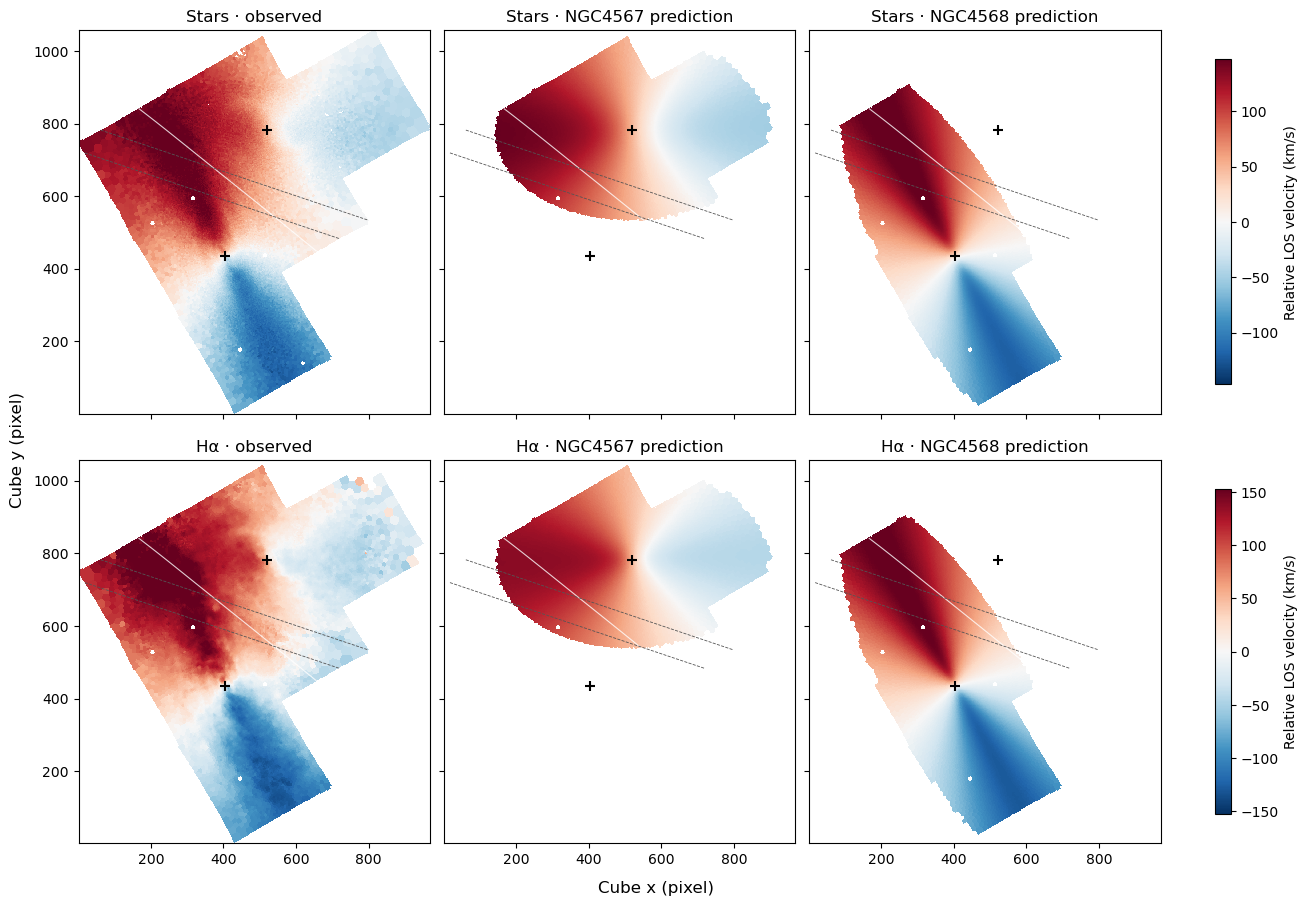

In [7]:

def bin_image(values):
    image = np.full((ny, nx), np.nan)
    image[footprint] = values[inverse]
    return image

fig, axes = plt.subplots(2, 3, figsize=(13, 9), layout="constrained", sharex=True, sharey=True)
for row, (tracer, (velocity, _, _)) in zip(axes, tracers.items()):
    qc, models = results[tracer, CUT]
    fields = [np.where(qc, velocity, np.nan), *[np.where(support, pred, np.nan) for pred, _, support in models]]
    vmax = np.nanpercentile(abs(np.concatenate(fields)), 97)
    for ax, data, title in zip(row, fields, ["observed", "NGC4567 prediction", "NGC4568 prediction"]):
        im = panel(ax, bin_image(data), f"{tracer} · {title}", show_light_edge=True,
                   cmap="RdBu_r", vmin=-vmax, vmax=vmax)
        ax.contour(on_sky(t), levels=[1 - CUT, CUT], colors="#555555", linestyles="--", linewidths=.6)
    fig.colorbar(im, ax=row, shrink=.8, label="Relative LOS velocity (km/s)")
fig.supxlabel("Cube x (pixel)")
fig.supylabel("Cube y (pixel)")
show_save(fig, "03_velocity_predictions")


## 4. Add velocity evidence to the R-band decision

Within a flexible band where the modeled flux ratio lies between 1:3 and 3:1, add the difference of the two velocity penalties to the photometric log odds. For tracer $k$ and galaxy $g$, the penalty is $\chi^2_{kg}=(v_k-v_{kg})^2/(e_k^2+s_{kg}^2)$. A tracer is omitted symmetrically when its measurement fails QC, either model is outside radial support, or both predictions miss by more than four effective standard deviations. The latter guard limits assignments driven by a disturbed centroid that neither model describes.

Version B uses weight 1 for stars. C adds Hα with weight 0.3. Compare with 0 and 0.5, and repeat using the alternative training strips. The logistic transform of the score difference is a **relative score for NGC4567**. The heuristic weights, model extrapolation and correlated tracers preclude a calibrated posterior interpretation. A score tie uses the A label, and an exact A tie goes to NGC4567. Count connected regions as a spatial diagnostic. Keep independent bin assignments so that the maps expose any fragmentation.

Write all three decisions as a signed score difference, with positive values favoring NGC4567 and negative values favoring NGC4568:

$$
D_A=\ln\frac{\sum I_{67}}{\sum I_{68}},\qquad
D_B=D_A+\Delta_\star,\qquad D_C=D_B+0.3\,\Delta_{\mathrm{H}\alpha}.
$$

Here $\Delta_k=(\chi^2_{k,68}-\chi^2_{k,67})/2$. A positive increment means NGC4567 has the smaller standardized squared residual for that tracer. The label changes only if the total crosses zero. A velocity residual is $v_{\rm obs}-v_{\rm model}$ in km/s. For example, a residual of $+20$ km/s means the bin is measured 20 km/s above that model's predicted velocity. The same bin has a different residual under each disk model.

The panels follow the score from A to B to C and show where each tracer actually enters. The lower-left panel also shows the full photometric band in which velocity terms are allowed. It is wider than the set of bins with usable velocity evidence. Open symbols locate two actual bins whose label flips, and the tables show the numbers used to make those decisions.


In [8]:
CUT = SEED_CUTS[0]
ETA = 0.3
ETA_GRID = [0., ETA, 0.5]
log_odds, pixel_odds = photo[CUT]

def galaxy_id(difference, tie=1):
    return np.where(difference > 0, 1, np.where(difference < 0, 2, tie)).astype(np.uint8)

def evidence(tracer, cut):
    velocity, error, _ = tracers[tracer]
    qc, models = results[tracer, cut]
    pred, scatter, support = map(np.asarray, zip(*models))
    residual = velocity - pred
    chi2 = residual**2 / (error**2 + scatter[:, None]**2)
    use = (qc & support.all(axis=0) & (np.min(chi2, axis=0) <= 16)
           & (abs(photo[cut][0]) <= np.log(3)))
    return np.where(use, 0.5 * (chi2[1] - chi2[0]), 0.), use, residual

ensemble = {}
for cut in SEED_CUTS:
    odds = photo[cut][0]
    star_term, star_use, star_resid = evidence("Stars", cut)
    gas_term, gas_use, gas_resid = evidence("Hα", cut)
    for eta in ETA_GRID:
        ensemble[cut, eta] = odds + star_term + eta * gas_term
star_term, star_use, star_resid = evidence("Stars", CUT)
gas_term, gas_use, gas_resid = evidence("Hα", CUT)
a = galaxy_id(log_odds)
b = galaxy_id(ensemble[CUT, 0.], a)
c = galaxy_id(ensemble[CUT, ETA], a)
trials = np.array([galaxy_id(d, galaxy_id(photo[cut][0])) for (cut, eta), d in ensemble.items()])
stability = (trials == c).mean(axis=0)
photo_trials = np.array([galaxy_id(p) for _, p in photo.values()])
pixel_label = galaxy_id(pixel_odds)
pixel_stability = (photo_trials == pixel_label).mean(axis=0)
score = expit(ensemble[CUT, ETA])
flex = abs(log_odds) <= np.log(3)
assert np.all(a[~flex] == c[~flex])
assert np.all(b[~gas_use] == c[~gas_use])
assert np.all(a[~star_use] == b[~star_use])

def from_bins(values, fill=np.nan, pixel_values=None):
    image = np.full((ny, nx), fill)
    if pixel_values is not None:
        image[usable_pixels] = pixel_values
    image[footprint] = values[inverse]
    return image

maps = {name: from_bins(values, 0, pixel_label) for name, values in zip("ABC", [a, b, c])}
score_map = from_bins(score, pixel_values=expit(pixel_odds))
stability_map = from_bins(stability, pixel_values=pixel_stability)
snr_map = from_bins(snr25, 0).astype(bool)
interface = (fraction >= 0.4) & (fraction <= 0.6)
rows = []
for name, mask in [("Full bins", np.ones(len(ids), dtype=bool)), ("Projected strip", interface),
                   ("Photometric flexible band", flex), ("Stellar S/N > 25", snr25)]:
    metrics = {"Bins": mask.sum(), "Spaxels": counts[mask].sum()}
    for key, condition in {"A to B": a != b, "B to C": b != c, "A to C": a != c,
                           "C relative score 0.4–0.6": abs(score - .5) <= .1,
                           "C switches in ensemble": stability < 1,
                           "Stellar evidence used": star_use, "Hα evidence used": gas_use}.items():
        selected = mask & condition
        metrics[f"{key} (bins)"] = selected.sum()
        metrics[f"{key} (spaxels)"] = counts[selected].sum()
    rows.append({"Region": name, **metrics})
diagnostics = pd.DataFrame(rows).set_index("Region")
display(diagnostics.T)
rows = []
for name, image in maps.items():
    for galaxy, number in zip(GALAXIES, [1, 2]):
        chosen = image == number
        regions, components = connected_components(chosen)
        sizes = np.bincount(regions[chosen], minlength=components + 1)
        rows.append({"Version": name, "Galaxy": galaxy, "Spaxels": chosen.sum(),
                     "S/N > 25 spaxels": (chosen & snr_map).sum(),
                     "4-connected regions": components,
                     "Spaxels outside largest region": chosen.sum() - sizes.max()})
display(pd.DataFrame(rows))
display(pd.DataFrame([
    {"Strip edge": cut, "Hα weight": eta,
     "Bins changed from C": np.count_nonzero(trial != c),
     "Spaxels changed from C": counts[trial != c].sum()}
    for (cut, eta), trial in zip(ensemble, trials)
]))

Region,Full bins,Projected strip,Photometric flexible band,Stellar S/N > 25
Bins,31846,2457,3749,31575
Spaxels,510118,58588,99009,435142
A to B (bins),366,206,366,365
A to B (spaxels),8118,3386,8118,7988
B to C (bins),128,54,128,127
B to C (spaxels),3491,1069,3491,3361
A to C (bins),424,222,424,424
A to C (spaxels),9573,3563,9573,9573
C relative score 0.4–0.6 (bins),586,291,586,562
C relative score 0.4–0.6 (spaxels),20871,7039,20871,13599


,Version,Galaxy,Spaxels,S/N > 25 spaxels,4-connected regions,Spaxels outside largest region
0,A,NGC4567,248079,198830,2,1
1,A,NGC4568,262039,236312,1,0
2,B,NGC4567,246909,197790,23,1170
3,B,NGC4568,263209,237352,25,827
4,C,NGC4567,246320,197071,23,1065
5,C,NGC4568,263798,238071,19,453


,Strip edge,Hα weight,Bins changed from C,Spaxels changed from C
0,0.60,0.0,128,3491
1,0.60,0.3,0,0
2,0.60,0.5,49,1075
3,0.55,0.0,181,4589
4,0.55,0.3,73,2032
5,0.55,0.5,50,1176
6,0.65,0.0,98,2936
7,0.65,0.3,47,1249
8,0.65,0.5,91,2249


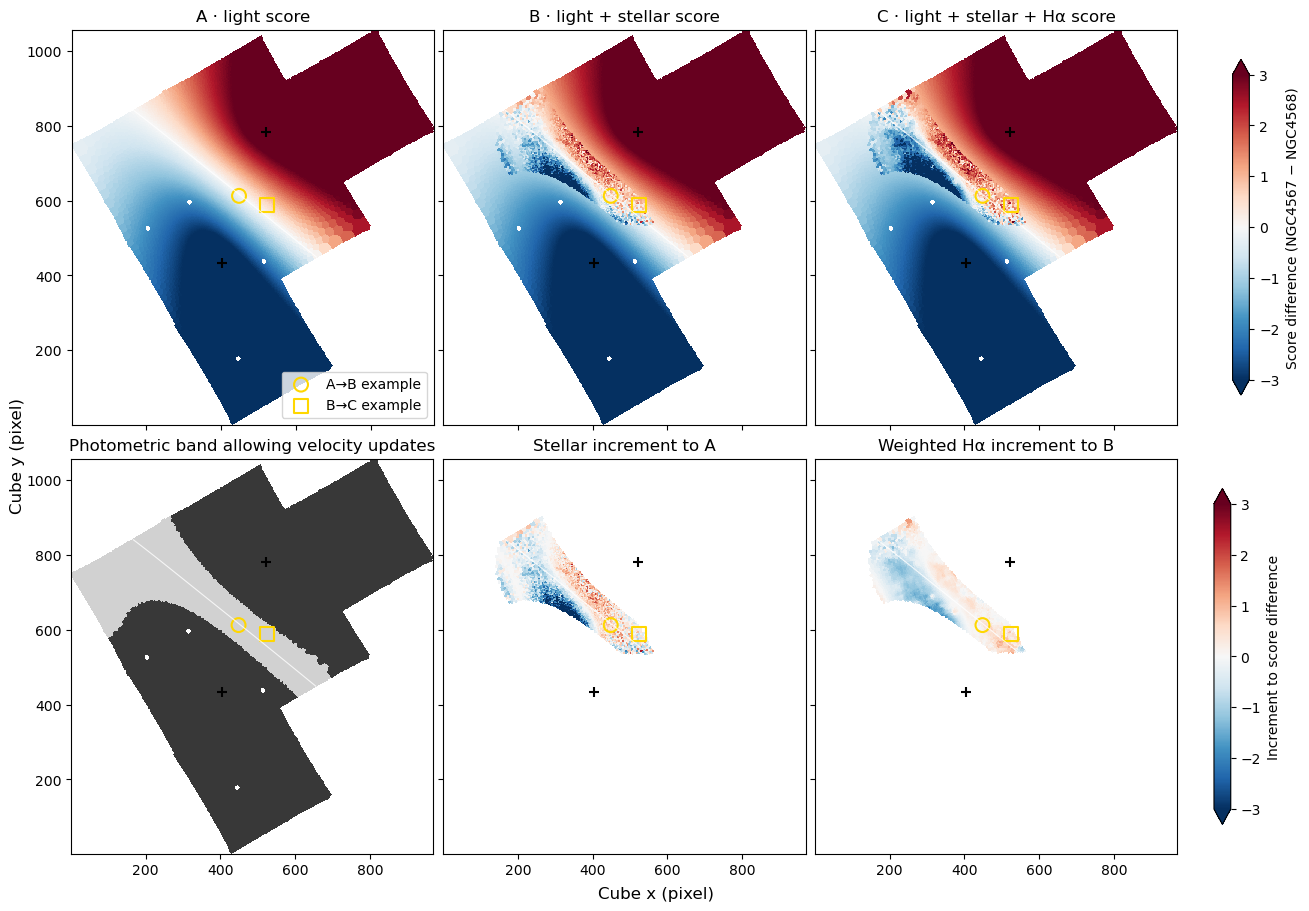

,Example,Bin ID,A,B,C,Light score,Stellar increment,Weighted Hα increment,B score,C score,Trials agreeing with C
0,A→B example,13828,NGC4568,NGC4567,NGC4567,-0.080,0.193,0.378,0.112,0.490,9/9
1,B→C example,15082,NGC4567,NGC4568,NGC4567,0.568,-0.697,0.333,-0.129,0.204,6/9


,Bin ID,Tracer,Galaxy model,Observed (km/s),Predicted (km/s),Residual (km/s),Effective error (km/s),χ²
0,13828,Stars,NGC4567,71.25,74.76,-3.51,9.00,0.15
1,13828,Stars,NGC4568,71.25,64.51,6.74,9.19,0.54
2,13828,Hα,NGC4567,83.18,73.26,9.92,11.74,0.71
3,13828,Hα,NGC4568,83.18,63.67,19.52,10.85,3.23
4,15082,Stars,NGC4567,35.30,48.26,-12.95,10.91,1.41
5,15082,Stars,NGC4568,35.30,36.72,-1.41,11.07,0.02
6,15082,Hα,NGC4567,51.85,48.00,3.85,12.02,0.10
7,15082,Hα,NGC4568,51.85,34.83,17.01,11.16,2.33


In [9]:

weighted_ha = ETA * gas_term
examples = []
for change in (a != b, b != c):
    candidates = np.flatnonzero(change & interface)
    examples.append(candidates[np.argmin(abs(fraction[candidates] - .5))])
example_styles = [("o", "A→B example"), ("s", "B→C example")]

fig, axes = plt.subplots(2, 3, figsize=(13, 9), layout="constrained", sharex=True, sharey=True)
for ax, values, title in zip(axes[0], [log_odds, ensemble[CUT, 0.], ensemble[CUT, ETA]],
                            ["A · light score", "B · light + stellar score", "C · light + stellar + Hα score"]):
    im = panel(ax, from_bins(values), title, show_light_edge=True, cmap="RdBu_r", vmin=-3, vmax=3)
fig.colorbar(im, ax=axes[0], shrink=.85, label="Score difference (NGC4567 − NGC4568)", extend="both")
band = from_bins(flex.astype(float))
panel(axes[1, 0], band, "Photometric band allowing velocity updates", show_light_edge=True,
      cmap=ListedColormap(["#383838", "#d1d1d1"]), vmin=0, vmax=1)
for ax, values, use, title in zip(axes[1, 1:], [star_term, weighted_ha], [star_use, gas_use],
                                 ["Stellar increment to A", "Weighted Hα increment to B"]):
    im = panel(ax, from_bins(np.where(use, values, np.nan)), title, show_light_edge=True,
               cmap="RdBu_r", vmin=-3, vmax=3)
fig.colorbar(im, ax=axes[1, 1:], shrink=.85, label="Increment to score difference", extend="both")
for ax in axes.flat:
    for j, (marker, label) in zip(examples, example_styles):
        ax.scatter(bx[j], by[j], marker=marker, s=100, facecolors="none", edgecolors="gold",
                   linewidth=1.5, label=label)
axes[0, 0].legend(loc="lower right")
fig.supxlabel("Cube x (pixel)")
fig.supylabel("Cube y (pixel)")
show_save(fig, "04_score_updates")

example_scores = []
example_residuals = []
for j, (_, example_label) in zip(examples, example_styles):
    example_scores.append({
        "Example": example_label, "Bin ID": int(ids[j]),
        "A": GALAXIES[a[j] - 1], "B": GALAXIES[b[j] - 1], "C": GALAXIES[c[j] - 1],
        "Light score": log_odds[j], "Stellar increment": star_term[j],
        "Weighted Hα increment": weighted_ha[j], "B score": ensemble[CUT, 0.][j],
        "C score": ensemble[CUT, ETA][j], "Trials agreeing with C": f"{int(round(9 * stability[j]))}/9",
    })
    for tracer, (velocity, error, _) in tracers.items():
        for galaxy, (pred, scatter, _) in zip(GALAXIES, results[tracer, CUT][1]):
            residual = velocity[j] - pred[j]
            example_residuals.append({"Bin ID": int(ids[j]), "Tracer": tracer, "Galaxy model": galaxy,
                                      "Observed (km/s)": velocity[j], "Predicted (km/s)": pred[j],
                                      "Residual (km/s)": residual, "Effective error (km/s)": np.hypot(error[j], scatter),
                                      "χ²": residual**2 / (error[j]**2 + scatter**2)})
with pd.option_context("display.max_columns", None):
    display(pd.DataFrame(example_scores).round(3))
    display(pd.DataFrame(example_residuals).round(2))



## 5. Inspect label changes, residuals and sensitivity

The A, B and C maps below all show the same thin white **pixel-level R-band** equality contour for reference. The label-change panel highlights exactly where adding stars or Hα changes the binary decision. The normalized C score shows how strongly the selected model favors NGC4567. A value near 0.5 marks a small score difference.

The fraction of trials agreeing is the number of runs that give a bin the **same binary label as fiducial C**, divided by nine. The nine runs are all combinations of three training strips and three Hα weights (0, 0.3, 0.5), including fiducial C. For example, 7/9 means two settings flip the label. A value of 1 indicates agreement across these settings. It measures sensitivity to the specified modeling choices. The runs share the same data, so this fraction cannot quantify the probability of true membership.

The residual maps subtract each disk model from the same observed velocity field. Red means observed velocity exceeds the prediction, blue means it falls below it, and near-white means a close match. Each row's two residual panels share a color scale. They show residuals for all bins passing the measurement cuts, including positions beyond a disk's radial support. Only bins passing the evidence criteria in Step 4 affect the split.


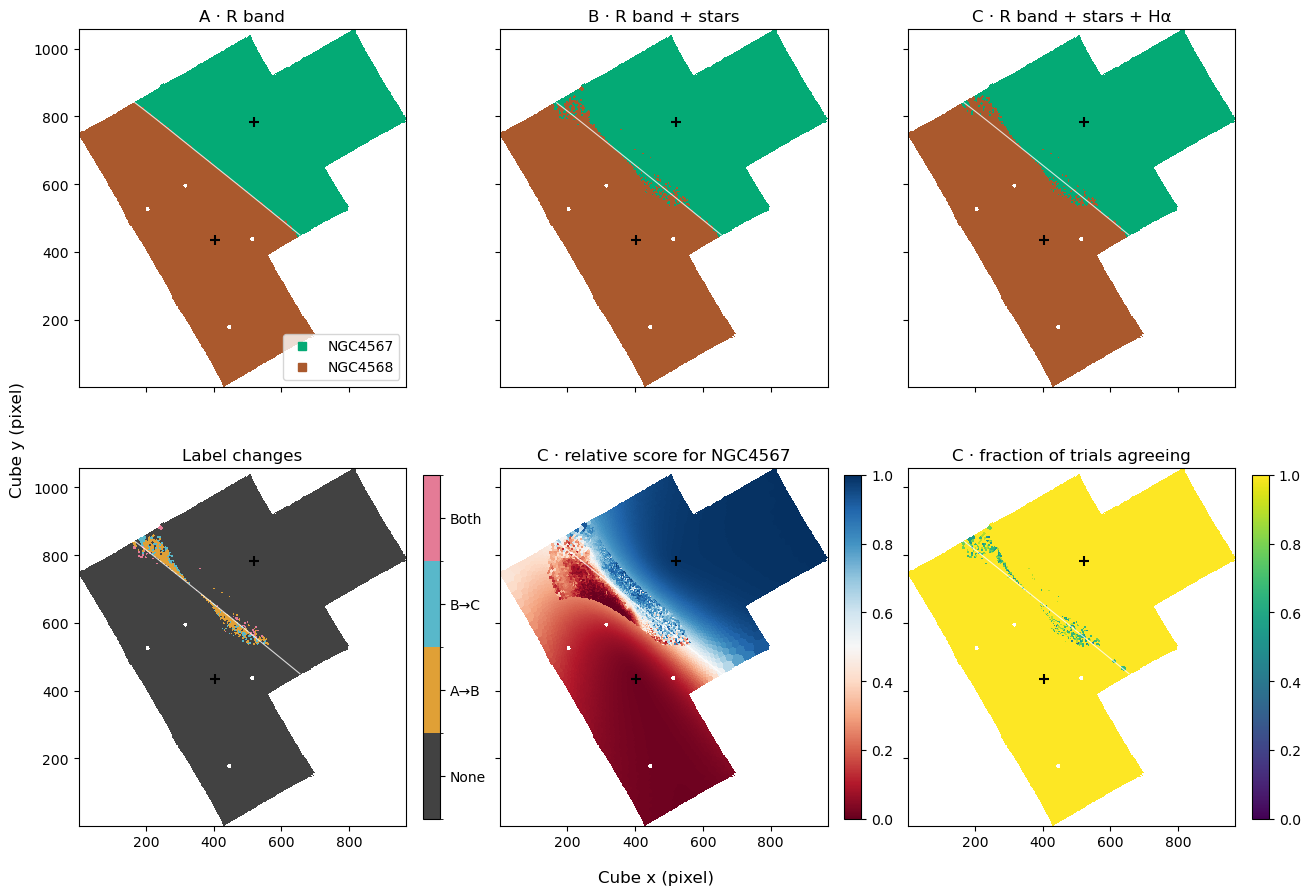

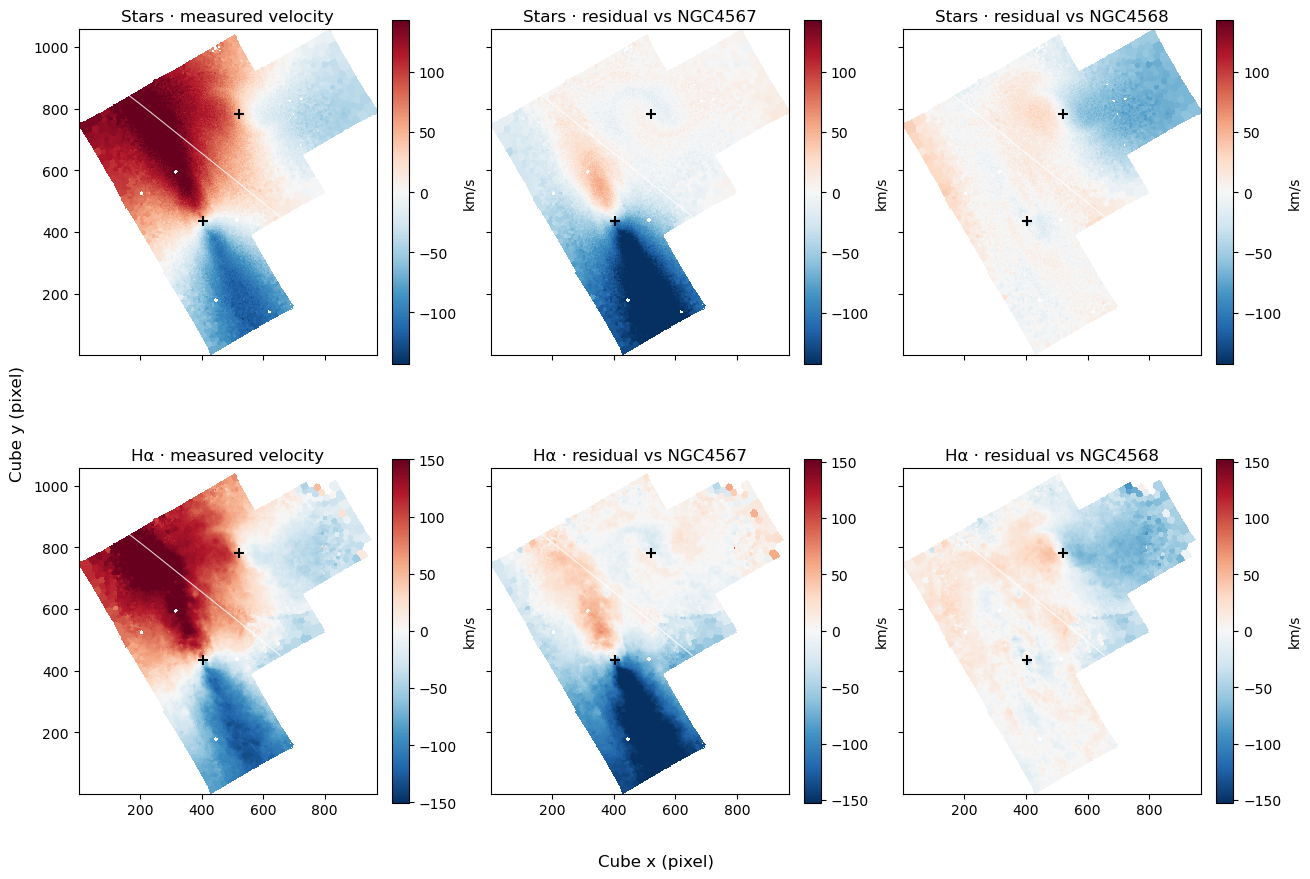

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(13, 9), layout="constrained", sharex=True, sharey=True)
for ax, (name, image), title in zip(axes[0], maps.items(), ["R band", "R band + stars", "R band + stars + Hα"]):
    panel(ax, np.ma.masked_equal(image, 0), f"{name} · {title}", show_light_edge=True, cmap=label_cmap, norm=label_norm)
axes[0, 0].legend(handles=[Line2D([], [], marker="s", linestyle="", color=colours[g], label=g)
                           for g in GALAXIES], loc="lower right")
changed = from_bins((a != b).astype(int) + 2 * (b != c))
im = panel(axes[1, 0], changed, "Label changes", show_light_edge=True, cmap=ListedColormap(["#424242", "#e0a036", "#58b8ca", "#e47b96"]),
           norm=BoundaryNorm(np.arange(-.5, 4.5), 4))
fig.colorbar(im, ax=axes[1, 0], ticks=range(4), shrink=.8).ax.set_yticklabels(["None", "A→B", "B→C", "Both"])
im = panel(axes[1, 1], score_map, "C · relative score for NGC4567", show_light_edge=True, cmap="RdBu", vmin=0, vmax=1)
fig.colorbar(im, ax=axes[1, 1], shrink=.8)
im = panel(axes[1, 2], stability_map, "C · fraction of trials agreeing", show_light_edge=True, cmap="viridis", vmin=0, vmax=1)
fig.colorbar(im, ax=axes[1, 2], shrink=.8)
fig.supxlabel("Cube x (pixel)")
fig.supylabel("Cube y (pixel)")
show_save(fig, "membership")

fig, axes = plt.subplots(2, 3, figsize=(13, 9), layout="constrained", sharex=True, sharey=True)
for row, (tracer, (vel, _, _)), resid in zip(axes, tracers.items(), [star_resid, gas_resid]):
    good = results[tracer, CUT][0]
    residual_limit = np.nanquantile(abs(resid[:, good]), .95)
    for ax, image, title in zip(row, [vel, resid[0], resid[1]],
                                 ["measured velocity", "residual vs NGC4567", "residual vs NGC4568"]):
        limit = np.nanquantile(abs(vel[good]), .95) if image is vel else residual_limit
        im = panel(ax, from_bins(np.where(good, image, np.nan)), f"{tracer} · {title}",
                   show_light_edge=True, cmap="RdBu_r", vmin=-limit, vmax=limit)
        fig.colorbar(im, ax=ax, shrink=.8, label="km/s")
fig.supxlabel("Cube x (pixel)")
fig.supylabel("Cube y (pixel)")
show_save(fig, "velocity_residuals")


## 6. Read the final binary map on the observed R image

The pink cut on the R image is the exact C boundary traced along pixel edges where adjacent usable pixels have different labels. The gold cut is the exact A boundary. The close-up shows the region containing the A, B and C label changes, with all three cuts drawn over the observed image. Masked pixels and the field perimeter are excluded from the cut tracing.


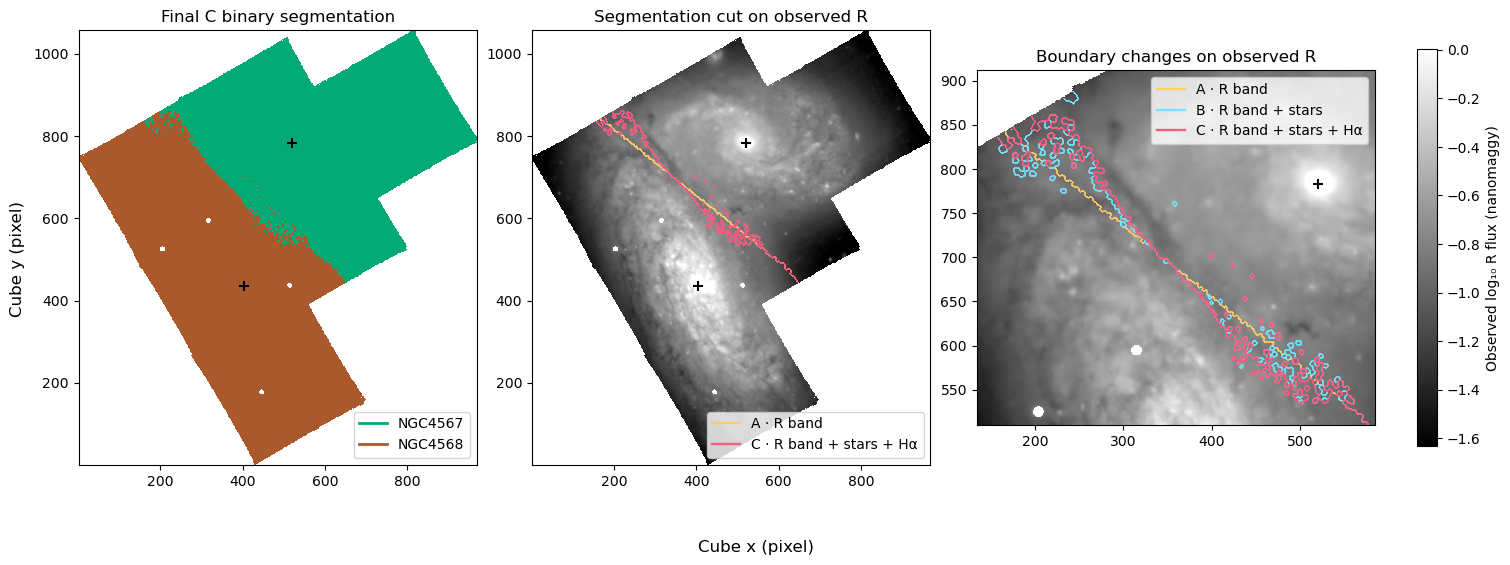

In [11]:

def label_edges(labels):
    left, right = labels[:, :-1], labels[:, 1:]
    y, x = np.nonzero((left > 0) & (right > 0) & (left != right))
    vertical = np.stack([np.column_stack([x + .5, y - .5]), np.column_stack([x + .5, y + .5])], axis=1)
    lower, upper = labels[:-1], labels[1:]
    y, x = np.nonzero((lower > 0) & (upper > 0) & (lower != upper))
    horizontal = np.stack([np.column_stack([x - .5, y + .5]), np.column_stack([x + .5, y + .5])], axis=1)
    return np.concatenate([vertical, horizontal])

edge_styles = {"A": ("#ffcc66", "-", "A · R band"),
               "B": ("#75e2ff", "-", "B · R band + stars"),
               "C": ("#fa5b83", "-", "C · R band + stars + Hα")}
edges = {name: label_edges(image) for name, image in maps.items()}

def add_cut(ax, name):
    color, style, label = edge_styles[name]
    ax.add_collection(LineCollection(edges[name], colors=color, linestyles=style, linewidths=1.25))
    return Line2D([], [], color=color, linestyle=style, lw=1.7, label=label)

fig, axes = plt.subplots(1, 3, figsize=(15, 6), layout="constrained")
panel(axes[0], np.ma.masked_equal(maps["C"], 0), "Final C binary segmentation", cmap=label_cmap, norm=label_norm)
axes[0].legend(handles=galaxy_handles, loc="lower right")
for ax, names, title in zip(axes[1:], ["CA", "CBA"], ["Segmentation cut on observed R", "Boundary changes on observed R"]):
    im = panel(ax, observed_light, title, cmap="gray", **light_limits)
    ax.legend(handles=[add_cut(ax, name) for name in names[::-1]], loc="upper right" if ax is axes[2] else "lower right")
y_change, x_change = np.nonzero((maps["A"] != maps["B"]) | (maps["B"] != maps["C"]))
axes[2].set(xlim=(x_change.min() - 24, x_change.max() + 24),
            ylim=(y_change.min() - 24, y_change.max() + 24))
fig.colorbar(im, ax=axes[1:], shrink=.7, label="Observed log₁₀ R flux (nanomaggy)")
fig.supxlabel("Cube x (pixel)")
fig.supylabel("Cube y (pixel)")
show_save(fig, "06_binary_map_and_R_overlay")


In [12]:
header = wcs.to_header()
header["CUBEID"] = CUBE
header["HAWEIGHT"] = ETA
header["PHOTMAX"] = (3., "Max modeled light ratio for velocity refinement")
header["STRIP"] = (CUT, "Training strip upper fractional edge")
header["COMMENT"] = "Galaxy labels: 0 outside usable footprint, 1 NGC4567, 2 NGC4568."
flag = from_bins(star_use.astype(np.uint8) + 2 * gas_use.astype(np.uint8), 0)
for image in maps.values():
    assert np.array_equal(image > 0, usable_pixels)
    assert np.isin(image, [0, 1, 2]).all()
assert np.array_equal(maps["C"][unbinned], maps["A"][unbinned])
assert np.isfinite(score_map[usable_pixels]).all()
assert np.all((score_map[usable_pixels] >= 0) & (score_map[usable_pixels] <= 1))

extensions = [
    ("GALAXY_ID", maps["C"].astype("u1"), "Version C"),
    ("GALAXY_ID_A", maps["A"].astype("u1"), "Version A"),
    ("GALAXY_ID_B", maps["B"].astype("u1"), "Version B"),
    ("SCORE_4567", score_map.astype("f4"), "Relative score for NGC4567"),
    ("STABILITY", stability_map.astype("f4"), "Fraction of trial labels agreeing"),
    ("EVIDENCE", flag.astype("u1"), "Bit 0: stellar term; bit 1: Halpha term"),
    ("BINNED", footprint.astype("u1"), "Pixel belongs to a valid Voronoi bin"),
    ("SNR_GT25", snr_map.astype("u1"), "Stellar post-fit SNR strictly above 25"),
]
images = [fits.PrimaryHDU()]
for name, image, description in extensions:
    hdu = fits.ImageHDU(image, header=header, name=name)
    hdu.header["HDUCLAS1"] = description
    images.append(hdu)
output_fits = OUT / f"{CUBE}_segmentation.fits"
fits.HDUList(images).writeto(output_fits, overwrite=True, checksum=True)

with fits.open(output_fits, checksum=True) as hdus:
    hdus.verify("exception")
    for name, image, _ in extensions:
        assert hdus[name].verify_checksum() == 1 and hdus[name].verify_datasum() == 1
        np.testing.assert_array_equal(hdus[name].data, image)
        saved_grid = WCS(hdus[name].header).celestial.pixel_to_world(grid_x, grid_y)
        assert np.max(sky_check.separation(saved_grid).arcsec) < 1e-4
    np.testing.assert_array_equal(hdus["GALAXY_ID"].data[footprint], c[inverse])
print(output_fits.relative_to(ROOT))

20261110_NGC4567_8_segmentation/NGC4567_8_segmentation.fits


## First-run interpretation

The footprint contains 31,846 bins and 510,118 spaxels. A to B changes 366 bins and 8,118 spaxels. B to C changes a further 128 bins and 3,491 spaxels (54 bins and 1,069 spaxels in the geometric interface strip). C assigns 246,320 spaxels to NGC4567 and 263,798 to NGC4568. Across the nine strip and Hα-weight combinations, 288 bins switch at least once.

The fiducial outer-region holdouts give a median absolute total-light residual of 0.061 dex, stellar predictive scatter of 7.9–8.1 km/s, and Hα scatter of 10.8–11.7 km/s. C leaves 1,518 spaxels outside the largest same-label region of their respective galaxy, compared with 1,997 for B. The changes are concentrated near the photometric boundary, but the holdouts test the outer training regions. They cannot establish which method assigns mixed sightlines correctly. Retain A and B alongside exploratory C when assessing sensitivity to the separation.